In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Задача 1. Графови невронни мрежи

## Лапласиан на граф

### 1.1. За графа на фигурата по-долу намерете:
- матрицата му на съседство;
- лапласиана му;
- базисните функции.
Покажете, че базисните функции са ортонормални и ги
визуализирайте.


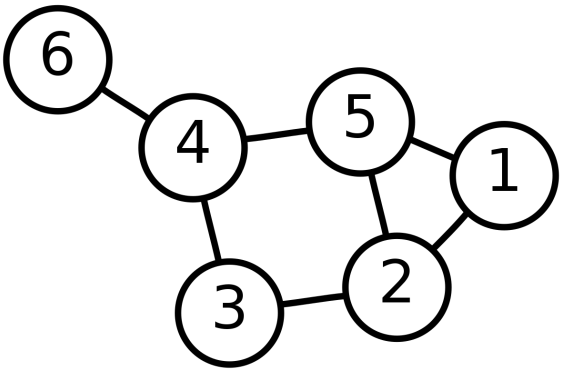

Извежда се матрицата на съседство и се изчисляват диагоналната матрица и лапласиана.

Намират се базисните функции. Те представляват набор от функции (или вектори), чрез които може да се опише всеки друг сигнал/вектор. При графа това са собствените вектори на Лапласиана. Те образуват ортонормален базис, както синусите и косинусите образуват базис за Фурие анализа.

Прави се проверка за ортонормалност.

Изчертава се графика на собствените вектори и съответните им стойности за всеки възел от графа.

Матрицата на съседство A:
 [[0. 1. 0. 0. 1. 0.]
 [1. 0. 1. 0. 1. 0.]
 [0. 1. 0. 1. 0. 0.]
 [0. 0. 1. 0. 1. 1.]
 [1. 1. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]]

Диагоналната матрица D (степени):
 [[2. 0. 0. 0. 0. 0.]
 [0. 3. 0. 0. 0. 0.]
 [0. 0. 2. 0. 0. 0.]
 [0. 0. 0. 3. 0. 0.]
 [0. 0. 0. 0. 3. 0.]
 [0. 0. 0. 0. 0. 1.]]

Лапласиан L = D - A:
 [[ 2. -1.  0.  0. -1.  0.]
 [-1.  3. -1.  0. -1.  0.]
 [ 0. -1.  2. -1.  0.  0.]
 [ 0.  0. -1.  3. -1. -1.]
 [-1. -1.  0. -1.  3.  0.]
 [ 0.  0.  0. -1.  0.  1.]]

Собствени стойности на L (по нарастване):
 [-3.02709247e-16  7.21586391e-01  1.68256939e+00  3.00000000e+00
  3.70462437e+00  4.89121985e+00]

Проверка на ортонормалността (U^T U):
 [[ 1.00000000e+00 -2.11072735e-16  1.30706876e-16 -1.77152020e-16
  -3.37291249e-16  2.82131285e-16]
 [-2.11072735e-16  1.00000000e+00 -1.98604867e-17  2.68102316e-16
   5.92609074e-17 -8.62385245e-18]
 [ 1.30706876e-16 -1.98604867e-17  1.00000000e+00  1.06916572e-16
  -1.35378531e-16  2.28049900e-17]
 [-1.771520

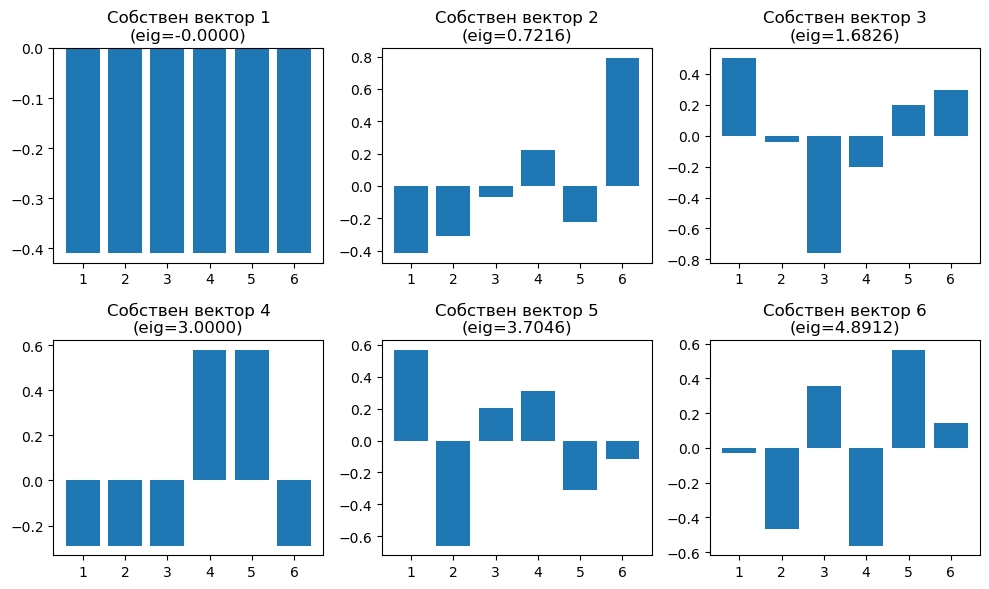

In [11]:
# Матрица на съседство
A = np.array([
    [0,1,0,0,1,0],
    [1,0,1,0,1,0],
    [0,1,0,1,0,0],
    [0,0,1,0,1,1],
    [1,1,0,1,0,0],
    [0,0,0,1,0,0]
], dtype=float)

# Диагонална матрица и лапласиан L = D - A
deg = np.sum(A, axis=1)
D = np.diag(deg)
L = D - A

# Собствени стойности и собствени вектори (симетрична матрица -> eigh)
eigvals, eigvecs = np.linalg.eigh(L)  # eigh връща сортирани собственни стойности

# Проверка за ортонормалност: U^T U трябва да е единична
U = eigvecs
orthogonality_check = U.T @ U  # близо до единична матрица

# Показване на резултатите
print("Матрицата на съседство A:\n", A)
print("\nДиагоналната матрица D (степени):\n", D)
print("\nЛапласиан L = D - A:\n", L)
print("\nСобствени стойности на L (по нарастване):\n", eigvals)
print("\nПроверка на ортонормалността (U^T U):\n", orthogonality_check)

# Графика на собственните вектори като bar plots
n = A.shape[0]
plt.figure(figsize=(10,6))
for k in range(n):
    plt.subplot(2,3,k+1)
    plt.bar(np.arange(1,n+1), U[:,k])
    plt.xticks(np.arange(1,n+1))
    plt.title(f"Собствен вектор {k+1}\n(eig={eigvals[k]:.4f})")
    plt.tight_layout()
plt.show()

### 1.2. Използвайки Kuzushiji-MNIST обучете и проверете:

 - Tочността при разпознаване на графова невронна мрежа с архитектура по ваше желание.
 - Операцията конволюция реализирайте посредством, т.нар конволюционна теорема с използване на Фурие образи

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision
from torchvision import datasets, transforms

import numpy as np
from scipy.spatial.distance import cdist
from scipy.sparse.linalg import eigsh

import time

In [28]:
# Settings

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RANDOM_SEED = 1
LEARNING_RATE = 0.05
NUM_EPOCHS = 50
BATCH_SIZE = 128
IMG_SIZE = 28
NUM_CLASSES = 10

torch.manual_seed(RANDOM_SEED)

#### Зареждане на данните

In [20]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.KMNIST(
    root="data_kmnist",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.KMNIST(
    root="data_kmnist",
    train=False,
    download=True,
    transform=transform
)

# Разделяме train → train + validation
train_data, valid_data = torch.utils.data.random_split(train_dataset, [55000, 5000])

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

# Checking the dataset
for images, labels in train_loader:
    print('Image batch dimensions:', images.shape)
    print('Image label dimensions:', labels.shape)
    break

Image batch dimensions: torch.Size([128, 1, 28, 28])
Image label dimensions: torch.Size([128])


#### Функция за създаване на матрица на съседство (граф)

Всеки пиксел е връх. Свързваме върхове близо един до друг.
Теглата на ребрата се намаляват с растящо разстояние между пикселите.

In [21]:
def precompute_adjacency_matrix(img_size):
    # Създава 2D масив
    # N = 28×28 = 784 върха (пиксели)
    col, row = np.meshgrid(np.arange(img_size), np.arange(img_size))
    
    # координати на всеки пиксел - нормализация в [0,1]
    coords = np.stack((row, col), axis=2).reshape(-1, 2) / img_size
        
    # матрица на разстоянията между всички пиксели
    dist = cdist(coords, coords, metric="euclidean")

    # Gaussian kernel за теглата
    sigma = 0.05 * np.pi
    A = np.exp(-dist / sigma**2)

    # премахване на много малките тегла - разреждане на графа
    A[A < 0.01] = 0

    return torch.from_numpy(A).float()

#### Графов нормализиран лапласиан

In [22]:
def get_graph_laplacian(A):
    A = A.numpy()
    N = A.shape[0]
    D = np.sum(A, axis=1)
    D_hat = np.diag((D + 1e-5)**(-0.5))
    L = np.eye(N) - D_hat @ A @ D_hat
    return torch.from_numpy(L).float()

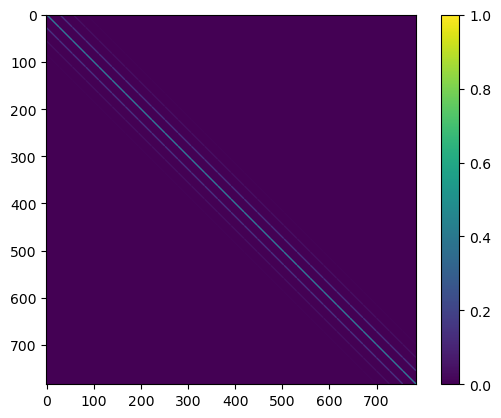

In [23]:
A = precompute_adjacency_matrix(28)
plt.imshow(A, vmin=0., vmax=1.)
plt.colorbar()
plt.show()

#### Модел: Графова спектрална конволюция

Ползва се филтър в спектралното пространство - матрица размер N×F, където:

N = брой пиксели (784),
F = брой филтри

Всеки пиксел има F филтърни стойности. Тези стойности започват случайно и се оптимизират по време на тренировка чрез backpropagation.

Входът и филтърът се превръщат в спектрални компоненти (графови честоти) чрез Фурие трансформация. Всяка входна честота се усилва или потиска според филтъра. Това е еквивалентно на конволюция в спектралното пространство.

Накрая изображението се превръща отново в пиксели чрез обратно Фурие преобразуване.

In [24]:
class SpectralGraphNet(nn.Module):
    def __init__(self, img_size=28, k_eigen=30, num_filters=4, num_classes=10):
        super().__init__()

        N = img_size * img_size   # 784

        # 1) конструиране на графа
        A = precompute_adjacency_matrix(img_size)
        L = get_graph_laplacian(A)

        # 2) собствени стойности и вектори (графов Фурие базис)
        #    which='SM' - най-малки собствени стойности
        Λ, V = eigsh(L.numpy(), k=k_eigen, which='SM')
        V = torch.from_numpy(V).float()  # (784 × k)

        # Филтър в спектралното пространство
        
        self.W_spectral = nn.Parameter(
            torch.randn(img_size*img_size, num_filters) * 0.1
        )

        # Финален линеен слой
        self.fc = nn.Linear(N * num_filters, num_classes)

        # регистрираме като buffer – не тренират
        self.register_buffer("V", V)
        self.register_buffer("L", L)
        self.register_buffer("A", A)

    def forward(self, x):
        # x: [B, 1, 28, 28]
        B = x.size(0)

        # преобразуваме входа в размер [B, N, 1]
        x_flat = x.view(B, -1, 1)

        # повтаряме V за всички batch елементи
        V = self.V.unsqueeze(0).expand(B, -1, -1)          # [B, N, k]
        V_T = self.V.t().unsqueeze(0).expand(B, -1, -1)    # [B, k, N]

        # Фурие трансформация
        # спектрален вход: X_hat = V^T x
        X_hat = torch.bmm(V_T, x_flat)                     # [B, k, 1]

        # спектрален филтър: W_hat = V^T W
        W_s = self.W_spectral.unsqueeze(0).expand(B, -1, -1)  # [B, N, F]
        W_hat = torch.bmm(V_T, W_s)                          # [B, k, F]

        # умножаваме поелементно → спектрална конволюция
        Y_hat = X_hat * W_hat                                # [B, k, F]

        # обратно Фурие преобразуване: Y = V Y_hat
        Y = torch.bmm(V, Y_hat)                              # [B, N, F]

        # flatten - classifier
        out = self.fc(Y.reshape(B, -1))
        return out

#### Създаване на модела

Създава се мрежа, която знае структурата на графа на пикселите.

In [25]:
model = SpectralGraphNet(
    img_size=IMG_SIZE,
    k_eigen=30,
    num_filters=4,
    num_classes=NUM_CLASSES
).to(DEVICE)

optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

#### Изчисляване на точността 

Изчисляване на точността на модела върху даден data loader (тестови или валидационен набор)

In [26]:
def compute_acc(model, loader):
    correct, total = 0, 0
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            preds = logits.argmax(1)  # най-вероятния клас за всеки приемр
            correct += (preds == y).sum()
            total += y.size(0)
    return 100 * correct.float() / total

#### Обучение

In [29]:
start = time.time()

for epoch in range(NUM_EPOCHS):
    model.train()
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        logits = model(x)
        loss = F.cross_entropy(logits, y)

        optimizer.zero_grad() # занулява градиентите от предишния батч
        loss.backward() # изчислява градиентите спрямо параметрите на модела (W_spectral и fc.weight/bias)
        optimizer.step() # актуализира параметрите, за да намали загубата

    # Оценка на точността след епоха
    train_acc = compute_acc(model, train_loader)
    valid_acc = compute_acc(model, valid_loader)

    print(f"Епоха {epoch+1:02d}/{NUM_EPOCHS}  Загуба={loss:.4f}  "
          f"TrainAcc={train_acc:.2f}%  ValAcc={valid_acc:.2f}%")

print("\n=== Тестова точност ===")
test_acc = compute_acc(model, test_loader)
print(f"Test Accuracy: {test_acc:.2f}%")

Епоха 01/50  Загуба=0.5645  TrainAcc=78.13%  ValAcc=77.38%
Епоха 02/50  Загуба=0.7708  TrainAcc=77.94%  ValAcc=77.10%
Епоха 03/50  Загуба=0.6946  TrainAcc=78.01%  ValAcc=77.18%
Епоха 04/50  Загуба=0.6466  TrainAcc=77.93%  ValAcc=77.34%
Епоха 05/50  Загуба=0.5721  TrainAcc=78.06%  ValAcc=77.06%
Епоха 06/50  Загуба=0.9108  TrainAcc=77.88%  ValAcc=77.12%
Епоха 07/50  Загуба=0.7500  TrainAcc=78.17%  ValAcc=77.30%
Епоха 08/50  Загуба=0.8653  TrainAcc=77.99%  ValAcc=77.30%
Епоха 09/50  Загуба=0.6386  TrainAcc=78.17%  ValAcc=77.42%
Епоха 10/50  Загуба=0.8233  TrainAcc=78.05%  ValAcc=77.56%
Епоха 11/50  Загуба=0.7533  TrainAcc=77.89%  ValAcc=76.92%
Епоха 12/50  Загуба=0.7078  TrainAcc=78.08%  ValAcc=77.24%
Епоха 13/50  Загуба=0.5425  TrainAcc=77.77%  ValAcc=76.92%
Епоха 14/50  Загуба=0.5811  TrainAcc=78.08%  ValAcc=77.32%
Епоха 15/50  Загуба=0.5824  TrainAcc=78.09%  ValAcc=77.24%
Епоха 16/50  Загуба=0.9507  TrainAcc=77.96%  ValAcc=77.18%
Епоха 17/50  Загуба=0.7385  TrainAcc=77.81%  ValAcc=77.0